In [95]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [96]:
data=pd.read_csv('password.csv',on_bad_lines='skip')

In [ ]:
def transform(data):
    data=data.dropna()
    data['pass_length']=data['password'].astype(str).str.len()
    data["has_uppercase"] = data["password"].str.contains(r"[A-Z]", na=False).map({True:1,False:0})
    data["has_lowercase"] = data["password"].str.contains(r"[a-z]", na=False).map({True:1,False:0})
    data["has_special"] = data["password"].str.contains(r"[^a-zA-Z0-9]", na=False).map({True:1,False:0})
    return data

In [ ]:
data=transform(data)

In [ ]:
freq=data['pass_length'].value_counts()

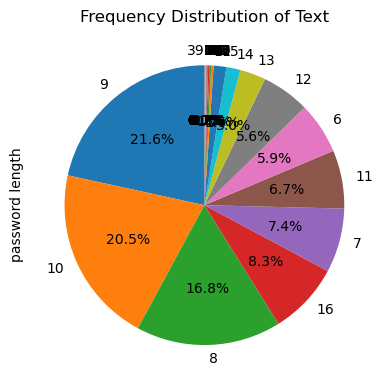

In [104]:
plt.figure(figsize=(4, 4))
freq.plot.pie(autopct="%1.1f%%", startangle=90)
plt.title("Frequency Distribution of Text")
plt.ylabel("password length")
plt.tight_layout()
plt.show()

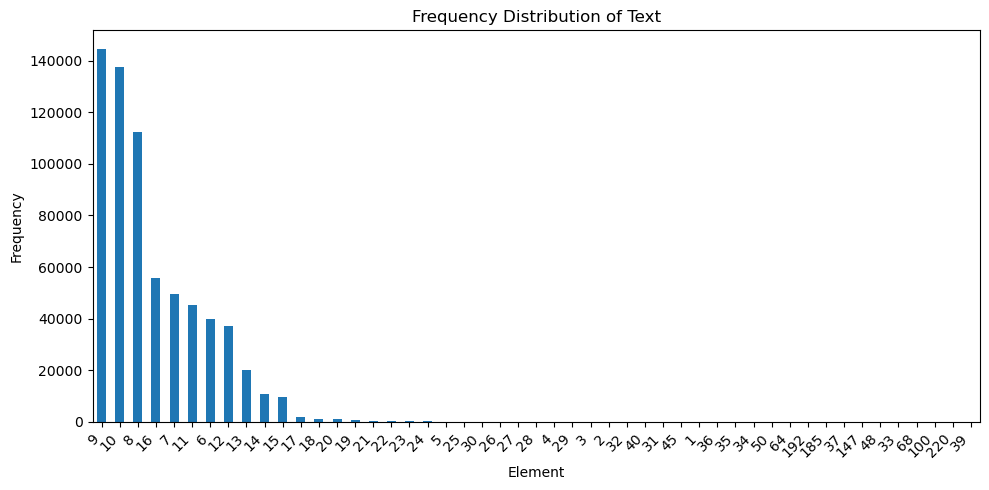

In [105]:
plt.figure(figsize=(10, 5))
freq.plot.bar()
plt.title("Frequency Distribution of Text")
plt.xlabel("Element")
plt.ylabel("Frequency")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

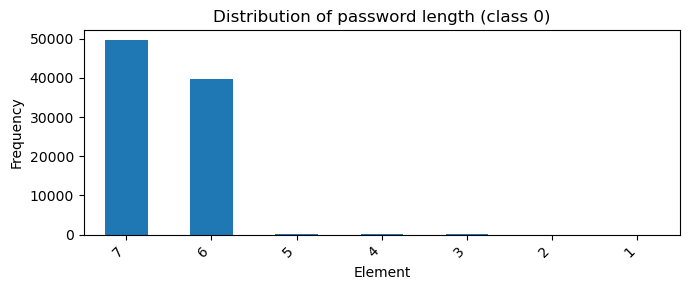

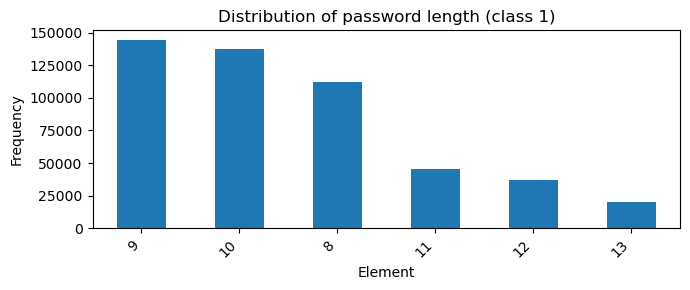

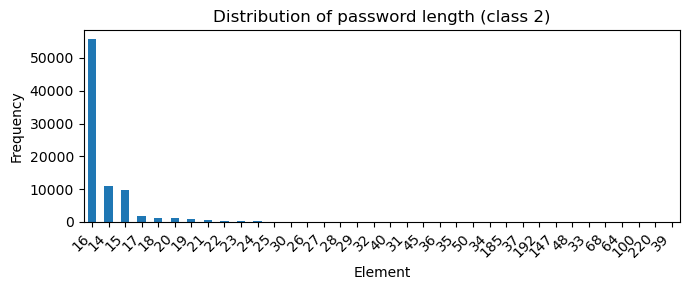

In [106]:
for i in range(0,3):
    frequ=data[data['strength']==i]['pass_length'].value_counts()
    plt.figure(figsize=(7, 3))
    frequ.plot.bar()
    plt.title(f"Distribution of password length (class {i})")
    plt.xlabel("Element")
    plt.ylabel("Frequency")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

### Password Criteria
##### 1.Pass length btw 1 and 8 == 0 , btw 9 and 13 ==1 and else 2
##### 2.Check if it has upper,lower,special characters

In [117]:
data

,password,strength,pass_length,has_uppercase,has_lowercase,has_special
0,kzde5577,1,8,0,1,0
1,kino3434,1,8,0,1,0
2,visi7k1yr,1,9,0,1,0
3,megzy123,1,8,0,1,0
4,lamborghin1,1,11,0,1,0
...,...,...,...,...,...,...
669635,10redtux10,1,10,0,1,0
669636,infrared1,1,9,0,1,0
669637,184520socram,1,12,0,1,0
669638,marken22a,1,9,0,1,0


In [110]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, classification_report

In [111]:
x=data.drop(['password','strength'],axis=1)
y=data['strength']

In [112]:
X_train, X_test, y_train, y_test = train_test_split(
    x, y, test_size=0.4, random_state=42, stratify=y
)

In [113]:

model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# 4. Make predictions
y_pred = model.predict(X_test)

# 5. Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average="macro", zero_division=0)
recall = recall_score(y_test, y_pred, average="macro", zero_division=0)

print("Accuracy:", round(accuracy, 4))
print("Precision (Macro):", round(precision, 4))
print("Recall (Macro):", round(recall, 4))

# 6. Detailed metrics for each class
print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
))


Accuracy: 1.0
Precision (Macro): 1.0
Recall (Macro): 1.0

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     35880
           1       1.00      1.00      1.00    198721
           2       1.00      1.00      1.00     33255

    accuracy                           1.00    267856
   macro avg       1.00      1.00      1.00    267856
weighted avg       1.00      1.00      1.00    267856



In [119]:

import pandas as pd

def predict_password(password, model):
    # Extract the same features used during training
    input_data = pd.DataFrame([{
        "pass_length": len(password),
        "has_uppercase": int(any(c.isascii() and c.isupper() for c in password)),
        "has_lowercase": int(any(c.isascii() and c.islower() for c in password)),
        "has_special": int(any(not c.isascii() or not c.isalnum() for c in password))
    }])

    # Predict the class
    prediction = model.predict(input_data)[0]

    print("Password:", password)
    print("Predicted class:", prediction)

    return prediction


# Take user input
while True:
    password = input("\nEnter a password (or 'exit' to stop): ")

    if password.lower() == "exit":
        break

    predict_password(password, model)


Password: vedang@_sawant02xy
Predicted class: 2
Password: 123483
Predicted class: 0
Password: vedanf_sawant
Predicted class: 1
Password: encqcneq**n@320
Predicted class: 2
